# Creation Corpus

Ce notebook sert à créer le corpus d'emails nettoyés qui servira à faire l'évaluation du workflow.

Je passe sur tous les emails de 2024 et j'injecte le token `__XGI_SPLIT_MAIL__` lorsque j'estime qu'il est nécessaire de faire un split entre la question et la réponse. Il peut y avoir plusieurs marqueurs, auquel cas, il faut considérer qu'il s'agit d'une conversation suivie avec plusieurs questions et plusieurs réponses.

## Demandes et actions observées

* trouver un document qui devrait être la (bxl) => trouver l'url du corpus.
* trouver un document inaccessible => forward vers
  * un dépot spécifique (comment savoir lequel ==> retrouver la province mais il y a des exceptions. Renvoi vers la page https://arch.arch.be/index.php?l=fr&m=en-pratique&r=nos-salles-de-
lecture)
  * aos_avg@arch.be pour les victimes de guerre.
  * police des étrangers si ressortissant étranger
  * si militaire: base de données du musée de l'armée
  * agr2 si archives coloniales, et collaboration
  * kbr si vieux livres plutot qu'archives
  * évêché si registre paroissial posterieur à 1795
  * fichier numérisé des soldats 1889--1930 et officiers apd 1900 (dans une salle de lecture)
  * reject si
      * ca concerne un doc qui n'a rien a voir avec la belgique
      * c'est une demande de versement pour des archives de particuliers
* document non trouvé => faq
* erreur dans un document / pas d'info => contacter les volontaires du projet
* recherche ac elt précis qui ne sont pas dans les fonds de base / cannot do => human takeover (filip, lieve)
* parvient pas à se connecter => activation manuelle
* mot de passe oublié => activation manuelle
* impossible de créer un nouveau compte => suppression de l'ancien compte bloqué
* login/mdp demandés => faq
* comment chercher => faq
* plus d'info a propos d'une page en lien => consulter + recherche
* contacté pour le compte de qqn d'autre en cc
* pas de demande claire => redirection faq

## Notes
Le actes des chambres (justice) sont conservés dans les provinces.

J'ai splitté les doc jusqu'au 300 inclus -- et je compte m'arreter la pour ce qui est de la 1e validation de mon poc.

un outil check account status pourrait s'avérer utile.

# Step 1: Constitution du dataset

La 1e étape entreprise consiste à manuellement lire les fichiers des conversations envoyées pour marquer clairement la limite entre les différents échanges de mails.

In [1]:
from pathlib import Path
import pandas as pd

MARKER = "__XGI_SPLIT_MAIL__"
FOLDER = Path("../corpus/digita_sent/2024/")

questions = []
responses = []

for file in filter(lambda x: int(x.name[:-4]) <= 300, FOLDER.glob("*.txt")):
    f = file.read_text(encoding="utf8")
    mails = f.split(MARKER)

    for i in range(0, len(mails)-1, 2):
        r = mails[i]
        q = mails[i+1]
        #print(q)
        #print("#"*100)
        #print(r)
        questions.append(q.strip())
        responses.append(r.strip())

df = pd.DataFrame.from_dict({"questions": questions, "responses": responses})
df.head()

,questions,responses
0,Van: communicat@arch.be <communicat@arch.be> \...,"Date: Wed, 03 Jul 2024 09:52:05 +0000\nTo: bar..."
1,De : communicat@arch.be <communicat@arch.be> \...,"Date: Fri, 05 Jul 2024 10:14:19 +0000\nTo: edm..."
2,**Van:** loekspruit@gmail.com <loekspruit@gmai...,"Date: Wed, 10 Jul 2024 11:33:54 +0000\nTo: loe..."
3,**De :** delphine kayaert <kayaertdelphine@gm...,"Date: Mon, 01 Jul 2024 13:44:22 +0000\nTo: ""de..."
4,De : communicat@arch.be <communicat@arch.be> \...,"Date: Mon, 01 Jul 2024 14:33:17 +0000\nTo: ""Am..."


In [2]:
len(df)

289

In [3]:
df.to_csv("corpus.csv")

In [4]:
from langchain_ollama.embeddings import OllamaEmbeddings


oe = OllamaEmbeddings(
    model    = "qwen3:8b",
    base_url = "http://localhost:11434"
)

em = oe.embed_documents(
    questions
)

In [5]:
import numpy as np

em = np.array(em)

In [6]:
from sklearn.cluster import HDBSCAN

clustering = HDBSCAN().fit_predict(em)
len(np.unique_counts(clustering).values)

8

In [9]:
from sklearn.manifold import TSNE
reduced = TSNE(random_state=42).fit_transform(em)

#from pacmap import PaCMAP
#reduced = PaCMAP().fit_transform(em)

#from umap import UMAP
#reduced = UMAP().fit_transform(em)

#from sklearn.decomposition import PCA
#reduced = PCA().fit_transform(em)

<Axes: xlabel='x', ylabel='y'>

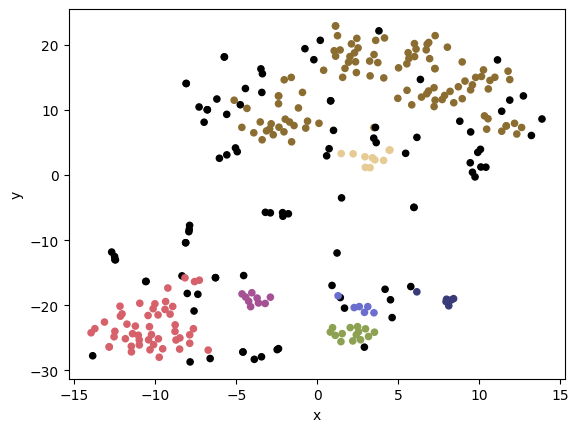

In [13]:
import matplotlib.pyplot as plt

palette = plt.get_cmap("tab20b", len(np.unique_counts(clustering).values))

colors  = [palette(c) if c >= 0 else '#000000' for c in clustering]
plot = pd.DataFrame.from_dict({"x": reduced[:,0].ravel(), "y": reduced[:,1].ravel(), "cluster": clustering})
plot.plot(kind="scatter", x="x", y="y", c=colors)

In [8]:
df["label_question"] = clustering

In [31]:
print(df[df["label_question"] == 5].iloc[2].questions)

**Van:** marina.smeyers@telenet.be <marina.smeyers@telenet.be>  
**Verzonden:** woensdag 26 juni 2024 14:46  
**Aan:** digita <digita@arch.be>  
**Onderwerp:** Genealogische bronnen - Registratie- of connectieprobleem



Goede namiddag, ik kan op agatha niet inloggen.  
Gebruikersnaam : MarinaConstantia  
Paswoord : 8202Nostalgia##  
  
Idem Search  
  
Kan U dit aub manueel in orde brengen ?  
Groetjes en alvast bedankt !  
Marina Smeyers

* * *

Voornaam : Marina Smeyers
